# Assignment: Gaussian mixture model in 2D, fitted with EM algorithm

## Problem statement

A Gaussian mixture with $k$ components in 2D has the density

$$p(x) = \sum_{j=1}^{k} w_j \, \mathcal{N}(x \mid \mu_j, \Sigma_j), \qquad w_j \ge 0, \quad \sum_j w_j = 1 .$$

Your task is to finish the class `GMM2D` below so that it can generate samples, evaluate its density and be **fitted to data** with the EM algorithm.

**Already implemented:** `__init__` and `starting_point` (a rough first guess for EM).

**You implement:**

1. `sample(n)` draws `n` points from the mixture and also returns the component each point came from.
2. `log_pdf(X)` returns $\log p(x_i)$ for every row $x_i$ of `X`.
3. `fit(X)` runs EM starting from the current parameters of the object and updates them in place.

You may add helper methods, but do not change the signatures of the existing ones (this is for plots later to work as expected).

### Notes on EM

The algorithm was derived in the lectures; each iteration has two steps.

- **E-step.** With the current parameters, compute the responsibilities: for every point, the probability that it came from each component.
- **M-step.** Re-estimate the weights, means and covariances, with every point weighted by its responsibilities.

Few notes-hints:

- At every iteration append the log-likelihood of the current parameters to `self.history`. EM never decreases it; if your `history` goes down, there is a bug.
- Work with logarithms of densities and sum over components with `scipy.special.logsumexp`, otherwise points far from every component underflow to zero.
- Add regularization of covarience estimates in M-step, i.e. add `reg` times the identity matrix to every covariance during the update. This keeps a covariance from becoming singular if/when a component collapses onto a few points.

### How to check your work

After the class is finished, the cells in sections 2 and 3 must run without changes.

- Section 2 fits the model to a sample from a known mixture and draws the log-likelihood history and the fitted density.
- Section 3 runs scikit-learn's EM from the same starting point. The log densities of the two models should differ by less than $10^{-4}$.


## 1. The `GMM2D` class

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.special import logsumexp
from scipy.stats import multivariate_normal

In [14]:
class GMM2D:
    """Gaussian mixture in 2D: p(x) = sum_j w_j * N(x | mu_j, Sigma_j)."""

    def __init__(self, weights, means, covs):
      self.weights = np.asarray(weights, dtype=float)  # (k,)
      self.means = np.asarray(means, dtype=float)      # (k, 2)
      self.covs = np.asarray(covs, dtype=float)        # (k, 2, 2)
      self.k = len(self.weights)

    @classmethod
    def starting_point(cls, X, k, rng=None):
      """A rough first guess to start EM from."""
      rng = np.random.default_rng(rng)
      means = X[rng.choice(len(X), size=k, replace=False)]
      covs = np.tile(np.cov(X.T), (k, 1, 1))
      return cls(np.full(k, 1 / k), means, covs)

    def sample(self, n, rng=None):
      """Draw n points from the mixture.
      Returns (X, labels): X of shape (n, 2) and labels of shape (n,),
      where labels[i] is the index of the component that produced X[i]."""
      rng = np.random.default_rng(rng)
      # TODO: Generate all random numbers with rng to get reproducible results
      # >>
      labels = rng.choice(self.k, size=n, p=self.weights)
      X = np.empty((n, 2))
      for j in range(self.k):
        idx = np.flatnonzero(labels == j)
        # Points of component j: N(mu_j, Sigma_j), generated with the same rng
        X[idx] = rng.multivariate_normal(self.means[j], self.covs[j], size=len(idx))
      return X, labels

    def log_pdf(self, X):
      """Log density at each row of X, shape (n,)."""
      # TODO: compute log(w_j) + log N(x_i | mu_j, Sigma_j) for every point i
      # and component j, then combine over j with logsumexp
      # >>
      res = np.empty((len(X), self.k))

      for j in range(self.k):
        res[:, j] = np.log(self.weights[j]) + multivariate_normal.logpdf(X, mean=self.means[j],
                                                            cov=self.covs[j])

      return res, logsumexp(res, axis=1)

    def fit(self, X, n_iter=200, tol=1e-6, reg=1e-6):
      """EM algorithm, starting from the current parameters.
      Stores the log-likelihood per iteration in self.history."""
      n = len(X)
      self.history = []
      for _ in range(n_iter):
        # E-step: responsibilities r[i, j] = P(component j | x_i)
        # TODO:
        # >>
        log_wp, log_px = self.log_pdf(X)
        r = np.exp(log_wp - log_px[:, None])

        # Log-likelihood of the current parameters; must never decrease
        self.history.append(log_px.sum())
        if len(self.history) > 1 and self.history[-1] - self.history[-2] < tol:
            break

        # M-step: weighted versions of the usual estimators
        # TODO:
        # >>
        nk = r.sum(axis=0)
        self.weights = nk/n   # new weights
        self.means = (r.T @ X) / nk[:, None]  # new means
        covs = np.empty((self.k, 2, 2))
        for j in range(self.k):
          d = X - self.means[j]
          covs[j] = (r[:, j, None] * d).T @ d / nk[j] + reg*np.eye(2)
        self.covs = covs    # new covariance matrix

      return self

## 2. Fit and pictures

Generate data from a known mixture and fit a new model to it.

In [15]:
# A known mixture to generate data from
true = GMM2D(
    weights=[0.5, 0.3, 0.2],
    means=[[0, 0], [4, 4], [-3, 4]],
    covs=[[[1, 0.6], [0.6, 1]], [[1, -0.5], [-0.5, 1.5]], [[0.5, 0], [0, 0.5]]],
)
X, labels = true.sample(3000, rng=0)

# Fit a new model, starting from a rough guess
model = GMM2D.starting_point(X, k=3, rng=1).fit(X)

Log-likelihood history and a summary of the fit. The fitted average log-likelihood should be close to (slightly above) the one of the true model.

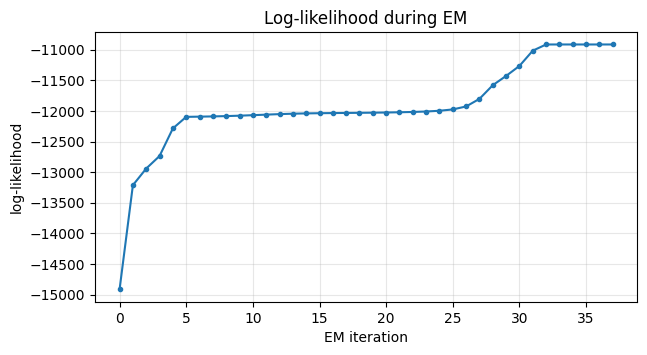

iterations: 38
monotone log-likelihood: True
avg log-lik  true: -3.6418  fitted: -3.6385
weights: [0.51  0.286 0.204]
means:
 [[-0.04  0.  ]
 [ 4.    4.  ]
 [-2.95  4.02]]


In [17]:
plt.figure(figsize=(7, 3.5))
plt.plot(model.history, marker="o", ms=3)
plt.xlabel("EM iteration")
plt.ylabel("log-likelihood")
plt.title("Log-likelihood during EM")
plt.grid(alpha=0.3)
plt.show()

print("iterations:", len(model.history))
print("monotone log-likelihood:", bool(np.all(np.diff(model.history) >= -1e-9)))
print("avg log-lik  true: %.4f  fitted: %.4f"
      % (true.log_pdf(X)[1].mean(), model.log_pdf(X)[1].mean()))
order = np.argsort(-model.weights)
print("weights:", np.round(model.weights[order], 3))
print("means:\n", np.round(model.means[order], 2))

The fitted density as a surface.

In [19]:
# Evaluate the fitted density on a grid; reused by the plots below
xs = np.linspace(X[:, 0].min() - 1.5, X[:, 0].max() + 1.5, 200)
ys = np.linspace(X[:, 1].min() - 1.5, X[:, 1].max() + 1.5, 200)
xx, yy = np.meshgrid(xs, ys)
grid = np.column_stack([xx.ravel(), yy.ravel()])
zz = np.exp(model.log_pdf(grid)[1]).reshape(xx.shape)

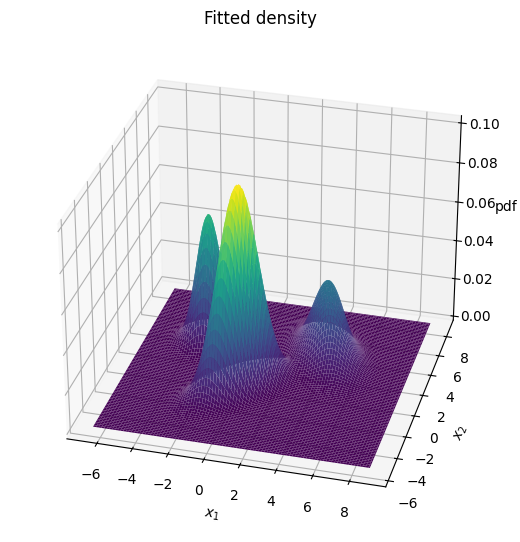

In [20]:
fig = plt.figure(figsize=(9, 6.5))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(xx, yy, zz, cmap="viridis", rstride=2, cstride=2, linewidth=0, antialiased=True)
ax.view_init(elev=30, azim=-75)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_zlabel("pdf")
ax.set_title("Fitted density")
plt.show()

Level lines of the fitted density, with the fitted centres marked.

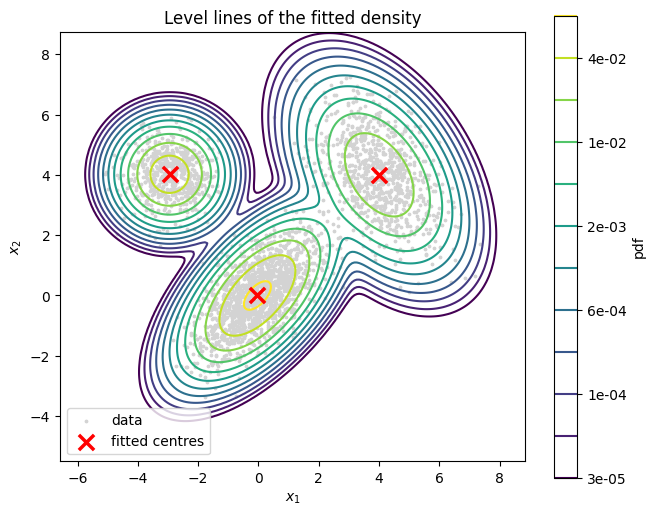

In [21]:
# Geometrically spaced levels: the high ones are ellipses around each centre,
# the low ones merge and wrap around several components at once
levels = zz.max() * np.geomspace(0.0003, 0.9, 12)

plt.figure(figsize=(7.5, 6))
plt.scatter(X[:, 0], X[:, 1], s=3, color="lightgray", label="data")
cs = plt.contour(xx, yy, zz, levels=levels, cmap="viridis", norm=LogNorm(), linewidths=1.5)
plt.colorbar(cs, label="pdf", format="%.0e")
plt.scatter(model.means[:, 0], model.means[:, 1], marker="x", s=120, color="red",
            linewidths=2.5, zorder=3, label="fitted centres")
plt.gca().set_aspect("equal")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Level lines of the fitted density")
plt.legend(loc="lower left")
plt.show()

## 3. Comparison with scikit-learn

`sklearn.mixture.GaussianMixture` runs the same EM algorithm. To compare fairly:

- both models start from the **same starting point**, otherwise they can converge to different local maxima;
- both run to full convergence (scikit-learn's default tolerance stops too early);
- the main check compares **densities**, which tests the whole model with one number;
- the parameters are compared directly as well: from the same starting point the components come out in the same order.

In [22]:
from sklearn.mixture import GaussianMixture

# The same seed gives the same starting point for both models
start = GMM2D.starting_point(X, k=3, rng=1)
sk = GaussianMixture(
    n_components=start.k,
    covariance_type="full",
    weights_init=start.weights,
    means_init=start.means,
    precisions_init=np.linalg.inv(start.covs),  # sklearn wants inverse covariances
    tol=1e-10, max_iter=1000, reg_covar=1e-6,
).fit(X)

mine = GMM2D.starting_point(X, k=3, rng=1).fit(X, n_iter=1000, tol=1e-10)

diff = np.abs(mine.log_pdf(X)[1] - sk.score_samples(X)).max()
print("avg log-lik  mine: %.6f  sklearn: %.6f" % (mine.log_pdf(X)[1].mean(), sk.score(X)))
print("iterations   mine: %d  sklearn: %d" % (len(mine.history), sk.n_iter_))
print("max |log_pdf difference|: %.2e" % diff)
print("PASSED" if diff < 1e-4 else "FAILED")

print()
print("max |parameter difference|")
print("  weights: %.2e" % np.abs(mine.weights - sk.weights_).max())
print("  means:   %.2e" % np.abs(mine.means - sk.means_).max())
print("  covs:    %.2e" % np.abs(mine.covs - sk.covariances_).max())

avg log-lik  mine: -3.638530  sklearn: -3.638530
iterations   mine: 41  sklearn: 38
max |log_pdf difference|: 4.33e-06
PASSED

max |parameter difference|
  weights: 6.99e-08
  means:   3.84e-07
  covs:    7.97e-07
